In [1]:
import re
from io import StringIO
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

In [ ]:
EXPECTED_COLS = [
    "id","case_number","date","block","iucr","primary_type","description",
    "location_description","arrest","domestic","beat","district","ward",
    "community_area","fbi_code","x_coordinate","y_coordinate","year",
    "updated_on","latitude","longitude","location"
]

BOOL_MAP = {"true": True, "false": False, True: True, False: False, 1: True, 0: False}

def coerce_bool(x):
    if pd.isna(x):
        return pd.NA
    if isinstance(x, bool):
        return x
    s = str(x).strip().lower()
    return BOOL_MAP.get(s, pd.NA)

def read_csv_robust(path="krime.csv"):
    try:
        df = pd.read_csv(
            path, engine="python",
            sep=",", quotechar='"', escapechar="\\",
            on_bad_lines="skip", dtype=str
        )
        if len(df.columns) >= 18:
            return df
    except Exception:
        pass

    with open(path, "r", encoding="utf-8", errors="replace") as f:
        lines = f.read().splitlines()

    if not lines:
        raise ValueError("CSV file is empty.")

    header = lines[0]
    repaired = [header]

    row_start = re.compile(r'^\s*"\d+"\s*,')

    for line in lines[1:]:
        if not line.strip():
            continue
        if row_start.match(line):
            repaired.append(line)
        else:
            repaired[-1] = repaired[-1] + " " + line.strip()

    df = pd.read_csv(
        StringIO("\n".join(repaired)),
        engine="python",
        sep=",", quotechar='"', escapechar="\\",
        on_bad_lines="skip", dtype=str
    )
    return df


In [ ]:
def standardize(df):
    df = df.copy()

    for c in EXPECTED_COLS:
        if c not in df.columns:
            df[c] = pd.NA

    for c in df.columns:
        df[c] = df[c].astype("string").str.strip()

    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["updated_on"] = pd.to_datetime(df["updated_on"], errors="coerce")

    df["arrest"] = df["arrest"].map(coerce_bool).astype("boolean")
    df["domestic"] = df["domestic"].map(coerce_bool).astype("boolean")

    num_cols = ["beat","district","ward","community_area","x_coordinate","y_coordinate","year","latitude","longitude"]
    for c in num_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    for c in ["primary_type","description","location_description","block","iucr","fbi_code"]:
        df[c] = df[c].astype("string").str.upper().str.strip()

    df = df.drop_duplicates(subset=["id"])

    df = df[df["date"].notna()].copy()

    df.loc[df["year"].isna(), "year"] = df.loc[df["year"].isna(), "date"].dt.year

    if "latitude" in df.columns and "longitude" in df.columns:
        bad = ~df["latitude"].between(41.0, 42.3) | ~df["longitude"].between(-88.6, -87.0)
        df.loc[bad, ["latitude","longitude"]] = pd.NA

    return df[EXPECTED_COLS].reset_index(drop=True)

df_raw = read_csv_robust("krime.csv")
df = standardize(df_raw)

print("Rows:", len(df), "| Columns:", df.shape[1])
df.head()


Rows: 3681 | Columns: 22


,id,case_number,date,block,iucr,primary_type,description,location_description,arrest,domestic,...,ward,community_area,fbi_code,x_coordinate,y_coordinate,year,updated_on,latitude,longitude,location
0,14029815,JJ490623,2025-11-13,066XX S SEELEY AVE,0497,BATTERY,AGGRAVATED DOMESTIC BATTERY - OTHER DANGEROUS ...,SIDEWALK,False,True,...,16,67,04B,1163841,1860572,2025,2025-11-20 15:47:13,41.773035,-87.674953,", (41.773034707, -87.674953485)"
1,14029403,JJ490135,2025-11-13,024XX S WASHTENAW AVE,0620,BURGLARY,UNLAWFUL ENTRY,APARTMENT,False,False,...,25,30,05,1158758,1887434,2025,2025-11-20 15:47:13,41.846853,-87.692853,", (41.846852738, -87.692852746)"
2,14027214,JJ487268,2025-11-13,056XX W ADAMS BLVD,0820,THEFT,$500 AND UNDER,VEHICLE NON-COMMERCIAL,False,False,...,29,25,06,1138503,1898542,2025,2025-11-20 15:47:13,41.877725,-87.76692,", (41.877725119, -87.766920112)"
3,14028439,JJ488711,2025-11-13,005XX E 91ST ST,1320,CRIMINAL DAMAGE,TO VEHICLE,STREET,False,False,...,8,44,14,1181424,1844758,2025,2025-11-20 15:47:13,41.729252,-87.610986,", (41.729251916, -87.610985691)"
4,14027169,JJ487265,2025-11-13,052XX S RICHMOND ST,0486,BATTERY,DOMESTIC BATTERY SIMPLE,APARTMENT,False,True,...,14,63,08B,1157599,1869694,2025,2025-11-20 15:47:13,41.798196,-87.697588,", (41.798195619, -87.697587999)"


In [ ]:
def add_features(df):
    out = df.copy()
    dt = out["date"]

    out["hour"] = dt.dt.hour
    out["dayofweek"] = dt.dt.dayofweek
    out["month"] = dt.dt.month
    out["day"] = dt.dt.day
    out["weekofyear"] = dt.dt.isocalendar().week.astype("Int64")

    out["is_weekend"] = out["dayofweek"].isin([5,6]).astype(int)
    out["is_night"] = out["hour"].isin([22,23,0,1,2,3,4,5]).astype(int)

    out["season"] = pd.cut(
        out["month"],
        bins=[0,2,5,8,11,12],
        labels=["winter","spring","summer","fall","winter2"],
        include_lowest=True
    ).astype("string").replace({"winter2":"winter"})

    out["lat_bin"] = pd.cut(out["latitude"], bins=20).astype("string")
    out["lon_bin"] = pd.cut(out["longitude"], bins=20).astype("string")

    return out

df2 = add_features(df)


In [5]:
display(df2.head())
print("\nArrest rate:", float(df2["arrest"].mean(skipna=True)))
print("Domestic rate:", float(df2["domestic"].mean(skipna=True)))

missing_pct = (df2.isna().mean() * 100).sort_values(ascending=False).round(2)
display(missing_pct.head(12))



,id,case_number,date,block,iucr,primary_type,description,location_description,arrest,domestic,...,hour,dayofweek,month,day,weekofyear,is_weekend,is_night,season,lat_bin,lon_bin
0,14029815,JJ490623,2025-11-13,066XX S SEELEY AVE,0497,BATTERY,AGGRAVATED DOMESTIC BATTERY - OTHER DANGEROUS ...,SIDEWALK,False,True,...,0,3,11,13,46,0,1,fall,"(41.758, 41.777]","(-87.678, -87.659]"
1,14029403,JJ490135,2025-11-13,024XX S WASHTENAW AVE,0620,BURGLARY,UNLAWFUL ENTRY,APARTMENT,False,False,...,0,3,11,13,46,0,1,fall,"(41.833, 41.852]","(-87.697, -87.678]"
2,14027214,JJ487268,2025-11-13,056XX W ADAMS BLVD,0820,THEFT,$500 AND UNDER,VEHICLE NON-COMMERCIAL,False,False,...,0,3,11,13,46,0,1,fall,"(41.871, 41.89]","(-87.773, -87.754]"
3,14028439,JJ488711,2025-11-13,005XX E 91ST ST,1320,CRIMINAL DAMAGE,TO VEHICLE,STREET,False,False,...,0,3,11,13,46,0,1,fall,"(41.72, 41.739]","(-87.621, -87.602]"
4,14027169,JJ487265,2025-11-13,052XX S RICHMOND ST,0486,BATTERY,DOMESTIC BATTERY SIMPLE,APARTMENT,False,True,...,0,3,11,13,46,0,1,fall,"(41.795, 41.814]","(-87.716, -87.697]"



Arrest rate: 0.14724259712034773
Domestic rate: 0.18853572398804672


y_coordinate            0.62
x_coordinate            0.62
lat_bin                 0.62
location                0.62
longitude               0.62
latitude                0.62
lon_bin                 0.62
location_description    0.35
iucr                    0.00
date                    0.00
season                  0.00
is_night                0.00
dtype: float64

In [6]:
def plot_barh_counts(series, title, topn=15):
    vc = series.dropna().astype("string").value_counts().head(topn)
    plt.figure(figsize=(10, 5))
    vc.sort_values().plot(kind="barh")
    plt.title(title)
    plt.xlabel("Count")
    plt.tight_layout()
    plt.show()

def plot_line_counts(x, title, xlabel):
    vc = x.value_counts().sort_index()
    plt.figure(figsize=(10, 4))
    plt.plot(vc.index, vc.values)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

def plot_bar_counts(x, title, xlabel):
    vc = x.value_counts().sort_index()
    plt.figure(figsize=(10, 4))
    plt.bar(vc.index.astype(str), vc.values)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Count")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

def plot_rate_by_category(df, cat_col, target_col="arrest", topn=15):
    tmp = df[[cat_col, target_col]].dropna().copy()
    tmp[cat_col] = tmp[cat_col].astype("string")
    grp = tmp.groupby(cat_col)[target_col].mean().sort_values(ascending=False)
    grp = grp.head(topn)

    plt.figure(figsize=(10, 5))
    plt.barh(grp.index.astype(str)[::-1], grp.values[::-1])
    plt.title(f"{target_col} rate by {cat_col} (top {topn})")
    plt.xlabel("Rate")
    plt.tight_layout()
    plt.show()

def plot_two_bars_rate(df, xcol, target="arrest"):
    tmp = df[[xcol, target]].dropna().copy()
    rate = tmp.groupby(xcol)[target].mean().sort_index()
    cnt = tmp[xcol].value_counts().sort_index()

    fig, ax1 = plt.subplots(figsize=(10,4))
    ax1.bar(rate.index.astype(str), rate.values)
    ax1.set_title(f"{target} rate by {xcol}")
    ax1.set_xlabel(xcol)
    ax1.set_ylabel("Rate")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10,4))
    plt.bar(cnt.index.astype(str), cnt.values)
    plt.title(f"Count by {xcol}")
    plt.xlabel(xcol)
    plt.ylabel("Count")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


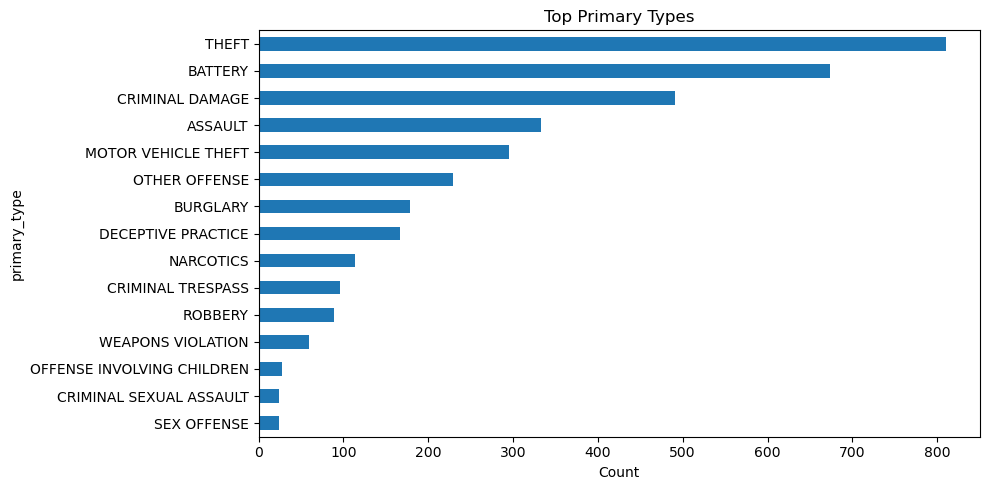

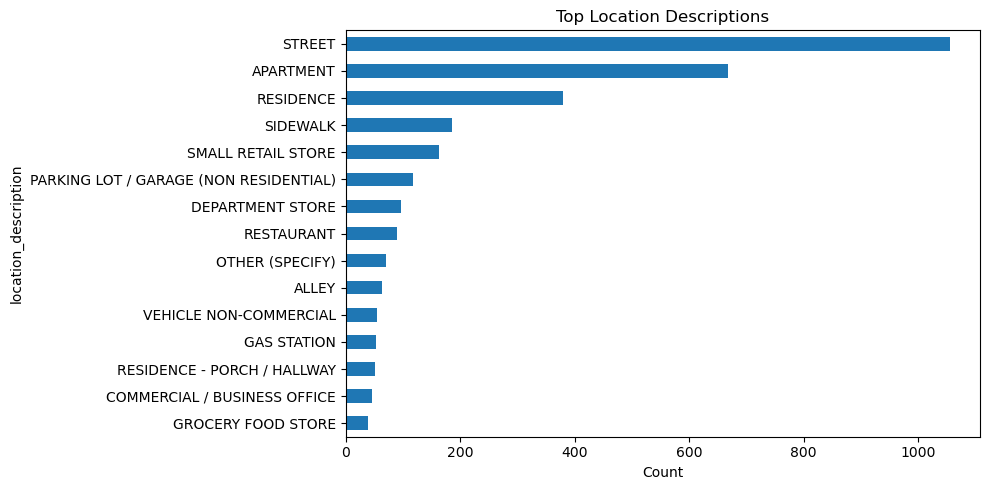

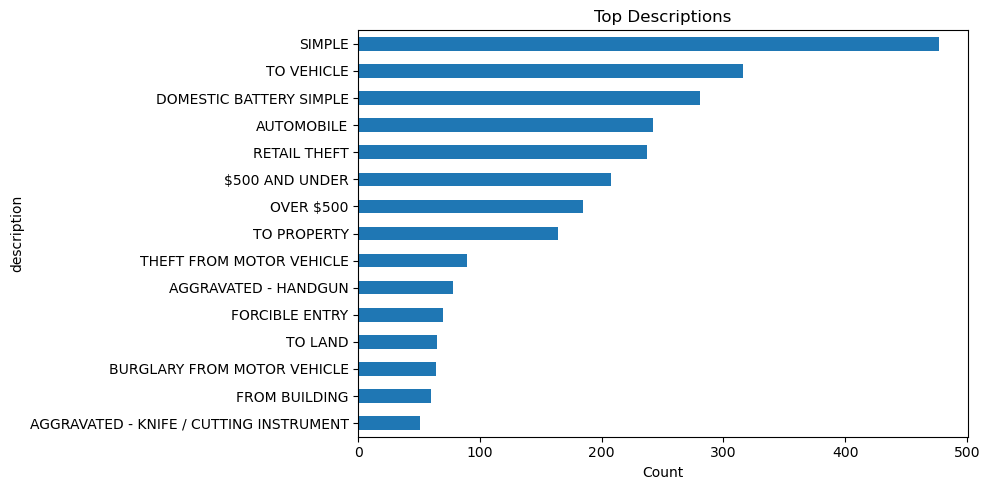

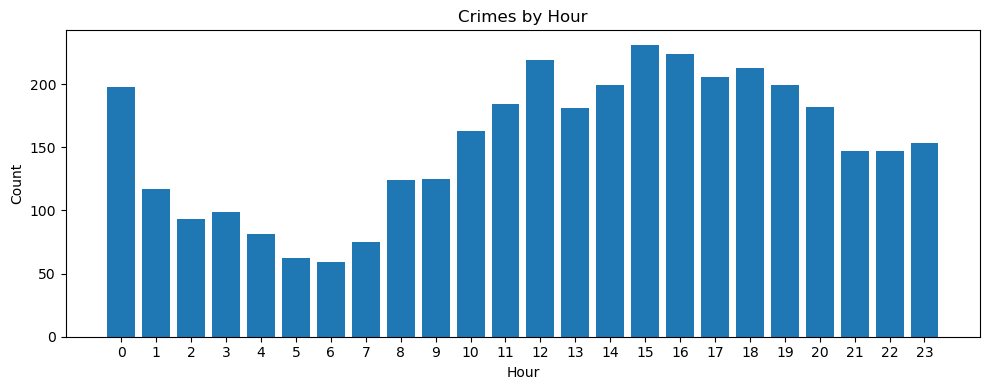

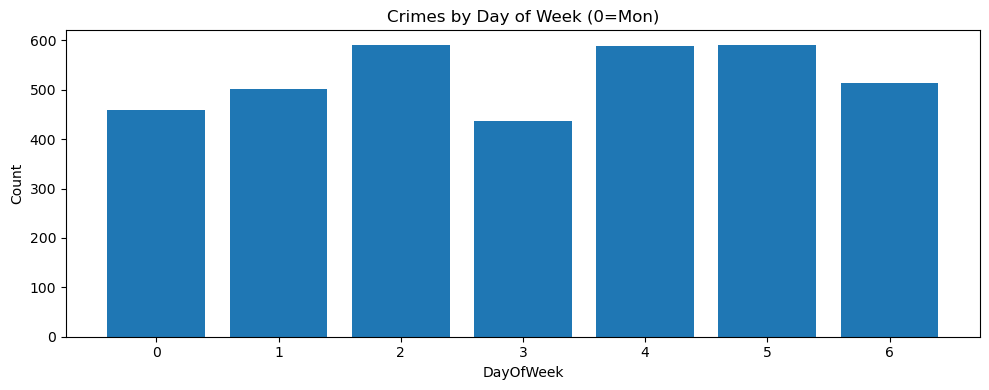

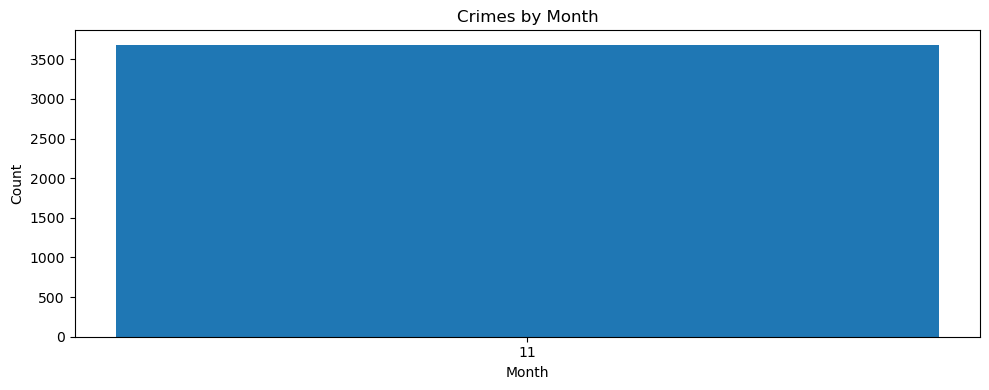

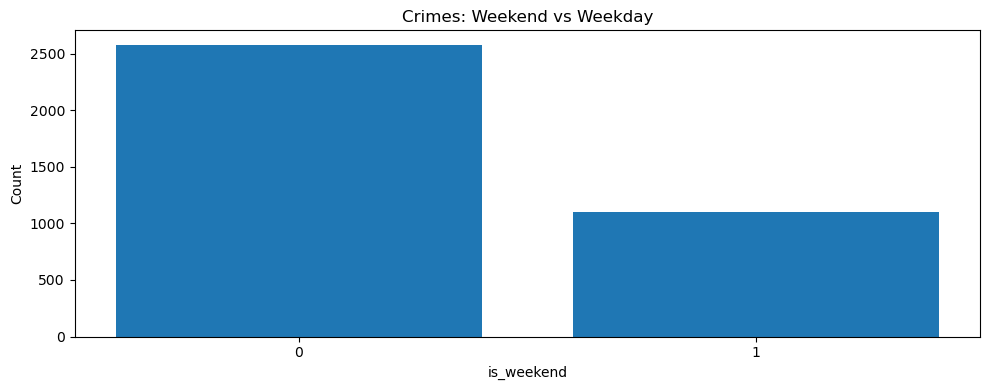

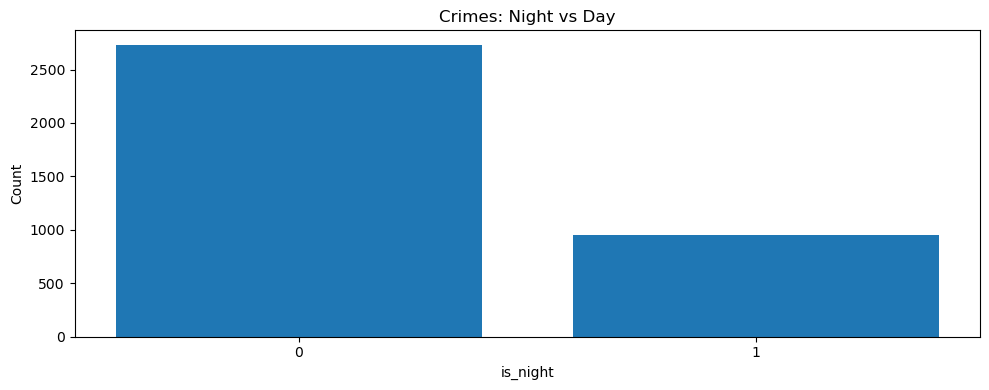

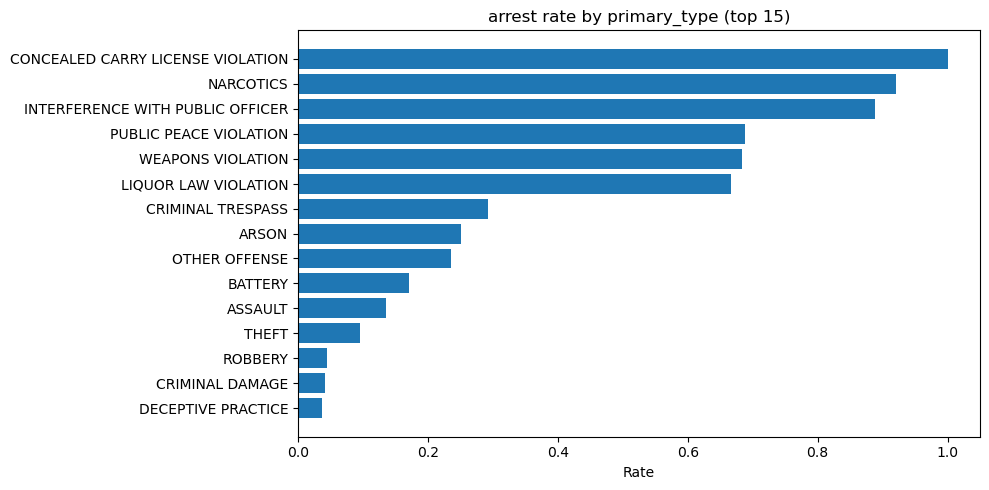

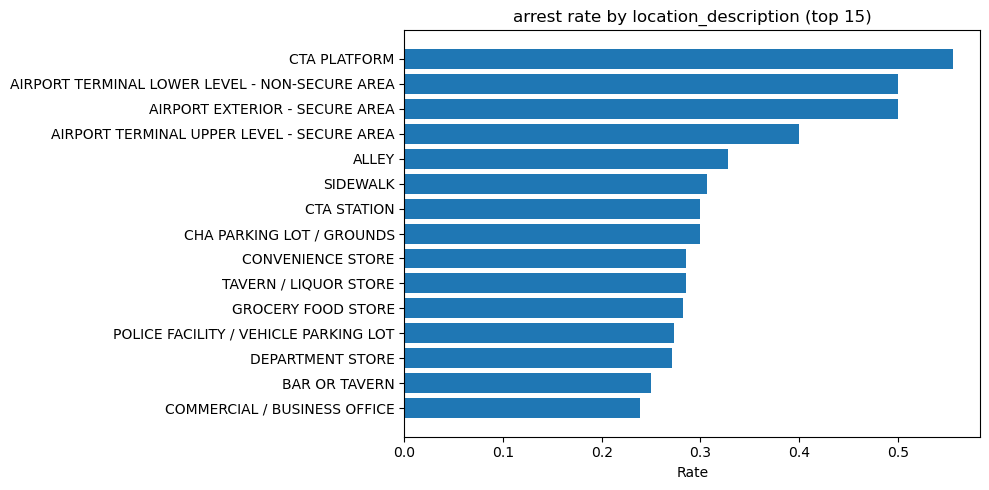

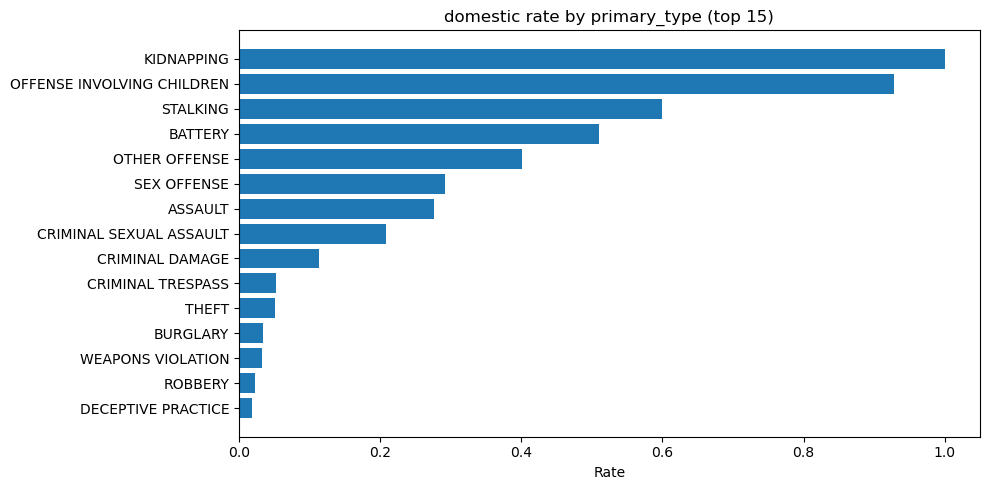

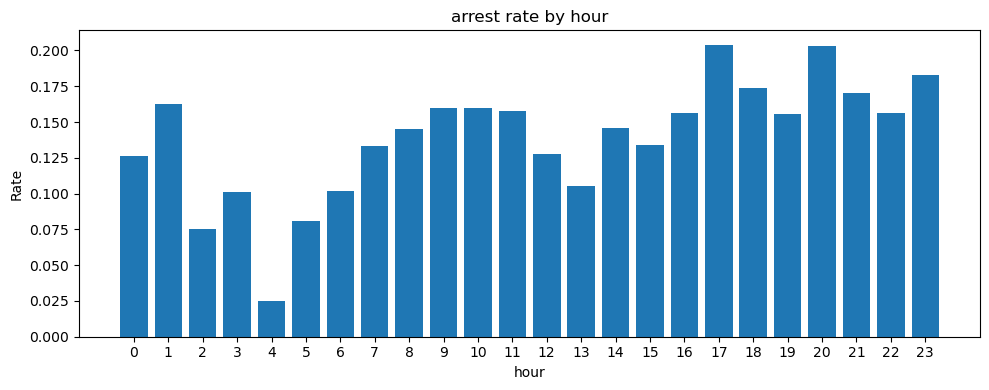

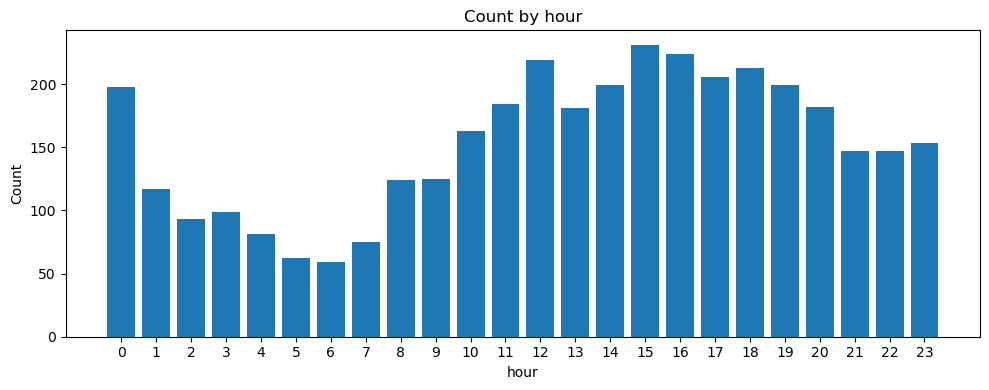

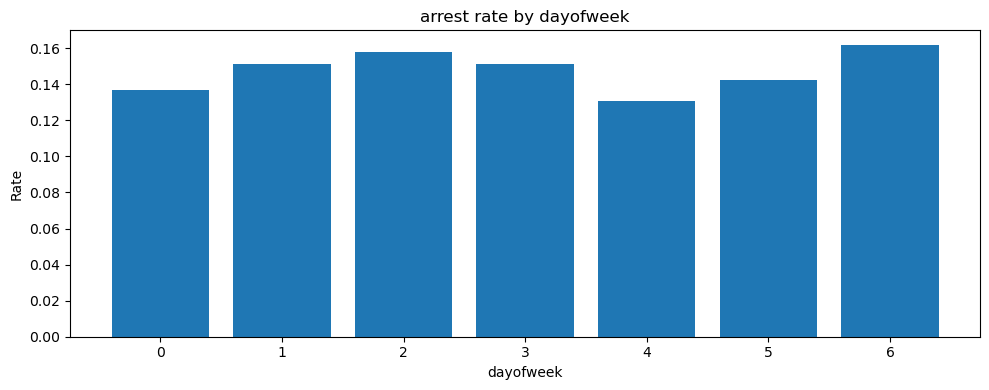

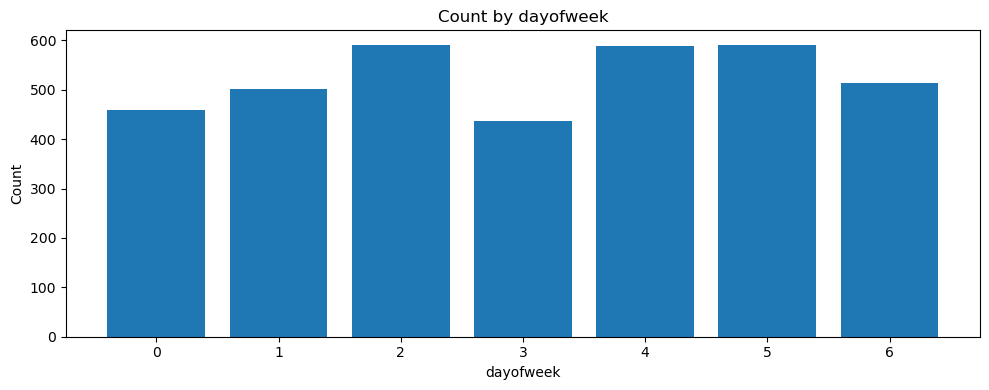

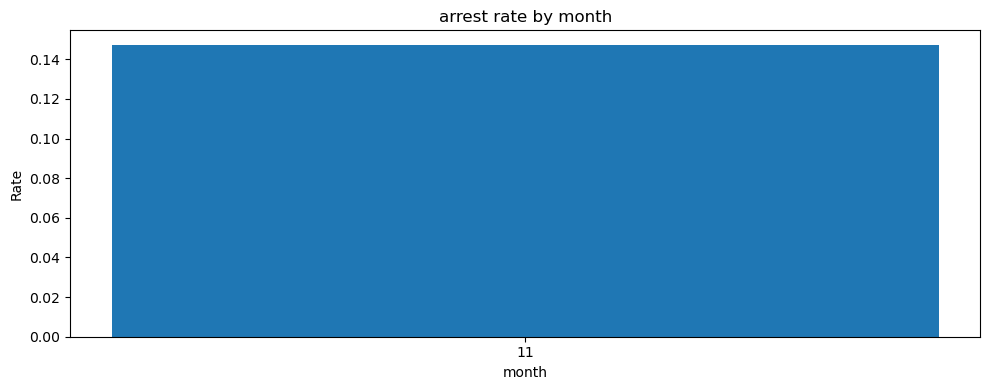

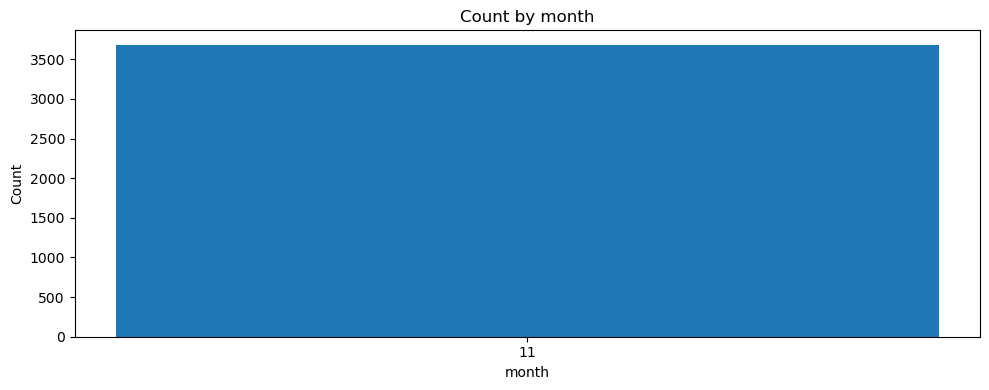

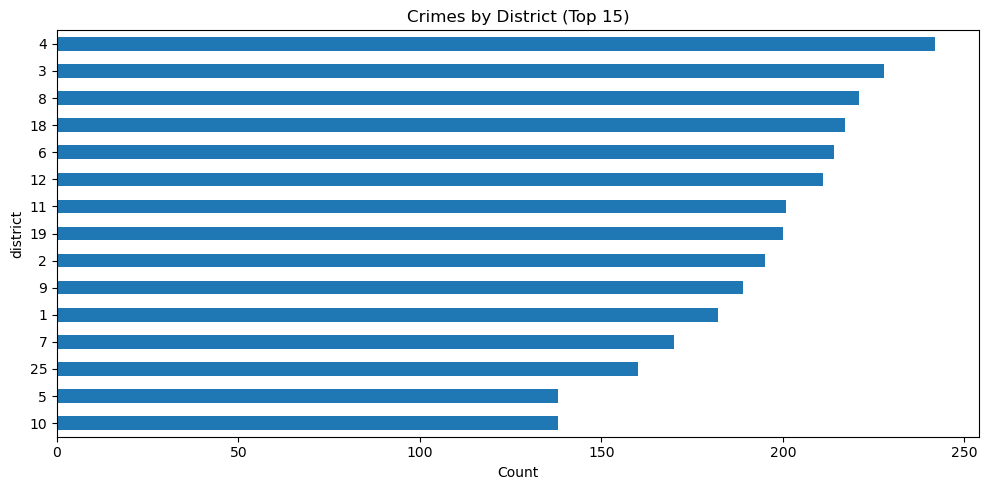

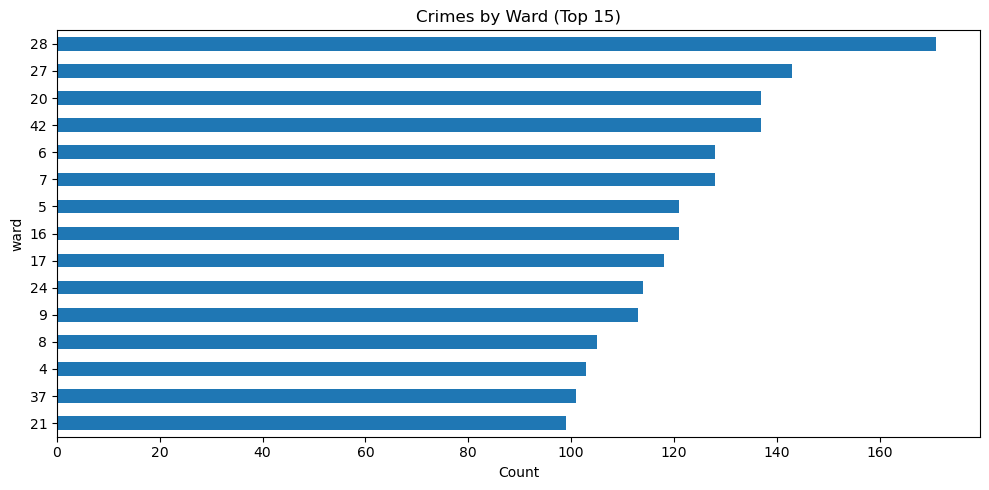

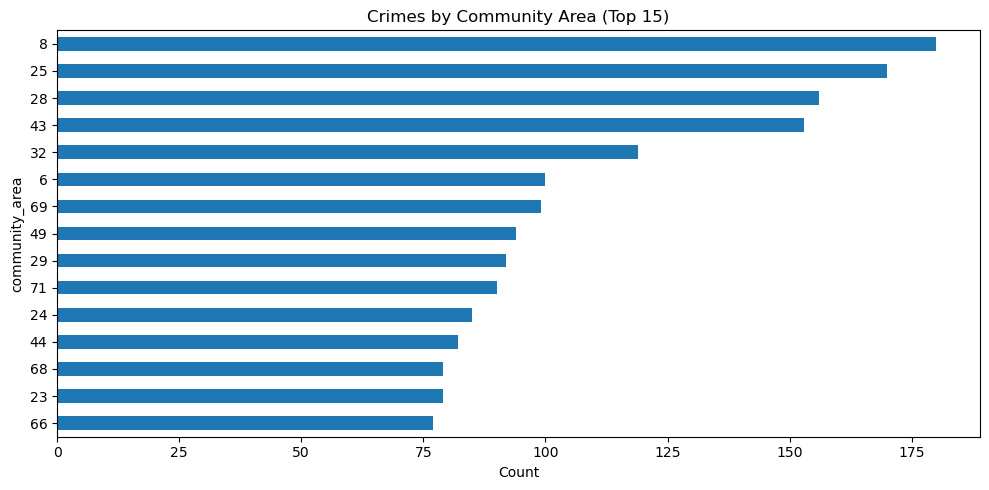

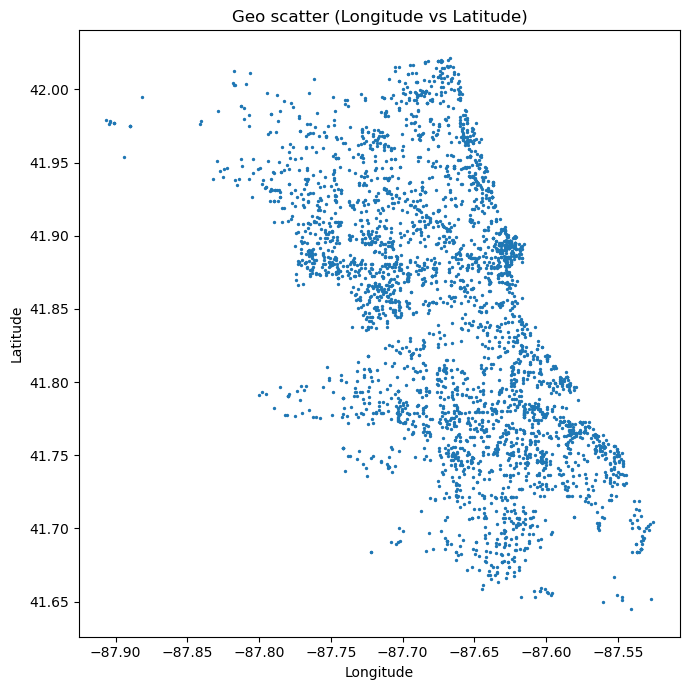

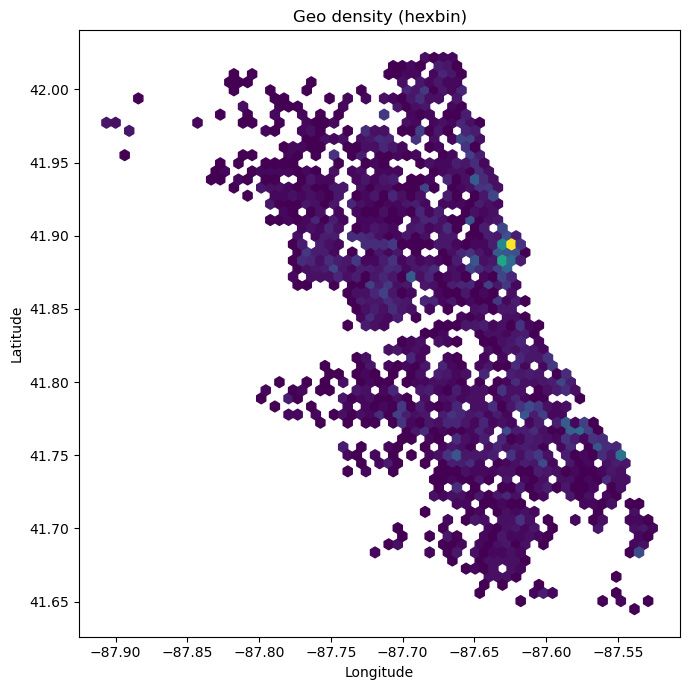

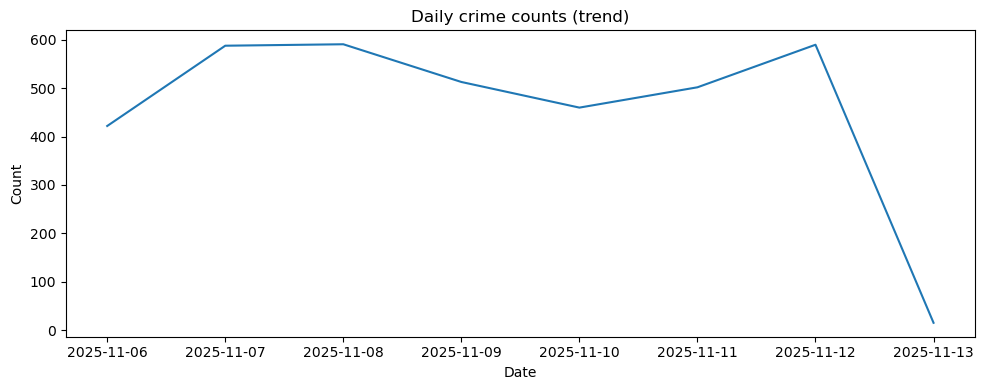

In [ ]:
plot_barh_counts(df2["primary_type"], "Top Primary Types", topn=15)
plot_barh_counts(df2["location_description"], "Top Location Descriptions", topn=15)
plot_barh_counts(df2["description"], "Top Descriptions", topn=15)

plot_bar_counts(df2["hour"], "Crimes by Hour", "Hour")
plot_bar_counts(df2["dayofweek"], "Crimes by Day of Week (0=Mon)", "DayOfWeek")
plot_bar_counts(df2["month"], "Crimes by Month", "Month")
plot_bar_counts(df2["is_weekend"], "Crimes: Weekend vs Weekday", "is_weekend")
plot_bar_counts(df2["is_night"], "Crimes: Night vs Day", "is_night")

plot_rate_by_category(df2, "primary_type", "arrest", topn=15)
plot_rate_by_category(df2, "location_description", "arrest", topn=15)
plot_rate_by_category(df2, "primary_type", "domestic", topn=15)

plot_two_bars_rate(df2, "hour", target="arrest")
plot_two_bars_rate(df2, "dayofweek", target="arrest")
plot_two_bars_rate(df2, "month", target="arrest")

plot_barh_counts(df2["district"].astype("Int64").astype("string"), "Crimes by District (Top 15)", topn=15)
plot_barh_counts(df2["ward"].astype("Int64").astype("string"), "Crimes by Ward (Top 15)", topn=15)
plot_barh_counts(df2["community_area"].astype("Int64").astype("string"), "Crimes by Community Area (Top 15)", topn=15)

geo = df2.dropna(subset=["latitude","longitude"]).copy()
if len(geo) > 0:
    plt.figure(figsize=(7, 7))
    plt.scatter(geo["longitude"], geo["latitude"], s=2)
    plt.title("Geo scatter (Longitude vs Latitude)")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.tight_layout()
    plt.show()

if len(geo) > 0:
    plt.figure(figsize=(7, 7))
    plt.hexbin(geo["longitude"], geo["latitude"], gridsize=60, mincnt=1)
    plt.title("Geo density (hexbin)")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.tight_layout()
    plt.show()

daily = df2.copy()
daily["date_only"] = daily["date"].dt.date
daily_counts = daily.groupby("date_only").size()
if len(daily_counts) > 3:
    plt.figure(figsize=(10,4))
    plt.plot(pd.to_datetime(daily_counts.index), daily_counts.values)
    plt.title("Daily crime counts (trend)")
    plt.xlabel("Date")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()


In [8]:
feature_cols = [
    "primary_type","description","location_description","iucr","fbi_code",
    "district","ward","community_area","beat",
    "season",
    "hour","dayofweek","month","is_weekend","is_night",
    "latitude","longitude",
    "domestic",
    "lat_bin","lon_bin"
]

df_ml = df2.copy()

y = df_ml["arrest"].astype("Int64")
mask = y.notna()
df_ml = df_ml[mask].copy()
y = y[mask].astype(int)

X = df_ml[feature_cols].copy()

print("ML rows:", len(X), " | Arrest rate:", y.mean().round(4))
display(X.head())



ML rows: 3681  | Arrest rate: 0.1472


,primary_type,description,location_description,iucr,fbi_code,district,ward,community_area,beat,season,hour,dayofweek,month,is_weekend,is_night,latitude,longitude,domestic,lat_bin,lon_bin
0,BATTERY,AGGRAVATED DOMESTIC BATTERY - OTHER DANGEROUS ...,SIDEWALK,0497,04B,7,16,67,726,fall,0,3,11,0,1,41.773035,-87.674953,True,"(41.758, 41.777]","(-87.678, -87.659]"
1,BURGLARY,UNLAWFUL ENTRY,APARTMENT,0620,05,10,25,30,1034,fall,0,3,11,0,1,41.846853,-87.692853,False,"(41.833, 41.852]","(-87.697, -87.678]"
2,THEFT,$500 AND UNDER,VEHICLE NON-COMMERCIAL,0820,06,15,29,25,1513,fall,0,3,11,0,1,41.877725,-87.76692,False,"(41.871, 41.89]","(-87.773, -87.754]"
3,CRIMINAL DAMAGE,TO VEHICLE,STREET,1320,14,6,8,44,633,fall,0,3,11,0,1,41.729252,-87.610986,False,"(41.72, 41.739]","(-87.621, -87.602]"
4,BATTERY,DOMESTIC BATTERY SIMPLE,APARTMENT,0486,08B,9,14,63,923,fall,0,3,11,0,1,41.798196,-87.697588,True,"(41.795, 41.814]","(-87.716, -87.697]"


In [ ]:
df_ml = df2.copy()

y = df_ml["arrest"].astype("Int64")
mask = y.notna()
df_ml = df_ml[mask].copy()
y = y[mask].astype(int)

feature_cols = [
    "primary_type","description","location_description","iucr","fbi_code",
    "district","ward","community_area","beat",
    "season",
    "hour","dayofweek","month","is_weekend","is_night",
    "latitude","longitude",
    "domestic",
    "lat_bin","lon_bin"
]

X = df_ml[feature_cols].copy()

X["domestic"] = X["domestic"].astype("boolean")
X["domestic"] = X["domestic"].fillna(False).astype(int)

cat_cols = ["primary_type","description","location_description","iucr","fbi_code","season","lat_bin","lon_bin"]
for c in cat_cols:
    X[c] = X[c].astype("string")

num_cols = ["district","ward","community_area","beat","hour","dayofweek","month","is_weekend","is_night","latitude","longitude","domestic"]
for c in num_cols:
    X[c] = pd.to_numeric(X[c], errors="coerce")

X = X.dropna(subset=["latitude", "longitude", "hour"]).copy()
y = y[X.index].copy()

for c in cat_cols:
    X[c] = X[c].fillna("MISSING")

print("ML rows:", len(X), " | Arrest rate:", y.mean().round(4))
display(X.head())


ML rows: 3658  | Arrest rate: 0.1482


,primary_type,description,location_description,iucr,fbi_code,district,ward,community_area,beat,season,hour,dayofweek,month,is_weekend,is_night,latitude,longitude,domestic,lat_bin,lon_bin
0,BATTERY,AGGRAVATED DOMESTIC BATTERY - OTHER DANGEROUS ...,SIDEWALK,0497,04B,7,16,67,726,fall,0,3,11,0,1,41.773035,-87.674953,1,"(41.758, 41.777]","(-87.678, -87.659]"
1,BURGLARY,UNLAWFUL ENTRY,APARTMENT,0620,05,10,25,30,1034,fall,0,3,11,0,1,41.846853,-87.692853,0,"(41.833, 41.852]","(-87.697, -87.678]"
2,THEFT,$500 AND UNDER,VEHICLE NON-COMMERCIAL,0820,06,15,29,25,1513,fall,0,3,11,0,1,41.877725,-87.76692,0,"(41.871, 41.89]","(-87.773, -87.754]"
3,CRIMINAL DAMAGE,TO VEHICLE,STREET,1320,14,6,8,44,633,fall,0,3,11,0,1,41.729252,-87.610986,0,"(41.72, 41.739]","(-87.621, -87.602]"
4,BATTERY,DOMESTIC BATTERY SIMPLE,APARTMENT,0486,08B,9,14,63,923,fall,0,3,11,0,1,41.798196,-87.697588,1,"(41.795, 41.814]","(-87.716, -87.697]"


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train set size:", X_train.shape[0])
print("Test set size:", X_test.shape[0])
print("Train arrest rate:", y_train.mean().round(4))
print("Test arrest rate:", y_test.mean().round(4))


Train set size: 2926
Test set size: 732
Train arrest rate: 0.1483
Test arrest rate: 0.1475


In [ ]:
cat_cols = ["primary_type","description","location_description","iucr","fbi_code","season","lat_bin","lon_bin"]
num_cols = ["district","ward","community_area","beat","hour","dayofweek","month","is_weekend","is_night","latitude","longitude","domestic"]

cat_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

num_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", cat_transformer, cat_cols),
        ("num", num_transformer, num_cols)
    ]
)

print("Preprocessor created successfully")


Preprocessor created successfully


In [ ]:
for c in num_cols:
    if X[c].isna().any():
        X[c] = X[c].fillna(X[c].median())
        print(f"Filled NaN in {c}")

for c in cat_cols:
    if X[c].isna().any():
        X[c] = X[c].fillna("MISSING")
        print(f"Filled NaN in {c}")

print("\nData ready for modeling")
print(X.isna().sum().sum(), "NaN values remaining")



Data ready for modeling
0 NaN values remaining


In [ ]:
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

for c in num_cols:
    if X_train_clean[c].isna().any():
        fill_val = X_train_clean[c].median()
        X_train_clean[c].fillna(fill_val, inplace=True)
        X_test_clean[c].fillna(fill_val, inplace=True)

for c in cat_cols:
    if X_train_clean[c].isna().any():
        X_train_clean[c].fillna("MISSING", inplace=True)
        X_test_clean[c].fillna("MISSING", inplace=True)

print("Train set clean:", X_train_clean.isna().sum().sum(), "NaN remaining")
print("Test set clean:", X_test_clean.isna().sum().sum(), "NaN remaining")

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_depth=7,
        learning_rate=0.1,
        max_iter=200,
        early_stopping=True,
        validation_fraction=0.2,
        n_iter_no_change=20,
        random_state=42,
        verbose=1
    ))
])

print("\nTraining model...")
model.fit(X_train_clean, y_train)
print("Model training completed!")


Train set clean: 0 NaN remaining
Test set clean: 0 NaN remaining

Training model...
Binning 0.009 GB of training data: 0.052 s
Binning 0.002 GB of validation data: 0.004 s
Fitting gradient boosted rounds:
[1/200] 1 tree, 18 leaves, max depth = 7, train loss: 0.38557, val loss: 0.38835, in 0.020s
[2/200] 1 tree, 19 leaves, max depth = 7, train loss: 0.36402, val loss: 0.36888, in 0.022s
[3/200] 1 tree, 18 leaves, max depth = 7, train loss: 0.34737, val loss: 0.35459, in 0.024s
[4/200] 1 tree, 20 leaves, max depth = 7, train loss: 0.33377, val loss: 0.34338, in 0.025s
[5/200] 1 tree, 19 leaves, max depth = 7, train loss: 0.32179, val loss: 0.33282, in 0.023s
[6/200] 1 tree, 20 leaves, max depth = 7, train loss: 0.31231, val loss: 0.32475, in 0.025s
[7/200] 1 tree, 18 leaves, max depth = 7, train loss: 0.30462, val loss: 0.31845, in 0.023s
[8/200] 1 tree, 20 leaves, max depth = 7, train loss: 0.29799, val loss: 0.31356, in 0.023s
[9/200] 1 tree, 20 leaves, max depth = 7, train loss: 0.292

In [ ]:
y_pred = model.predict(X_test_clean)
y_pred_proba = model.predict_proba(X_test_clean)[:, 1]

y_train_pred = model.predict(X_train_clean)
y_train_pred_proba = model.predict_proba(X_train_clean)[:, 1]

print("Predictions generated!")
print("Sample predictions (first 10 test samples):")
print("Actual:", y_test.values[:10])
print("Predicted:", y_pred[:10])
print("Probability of arrest:", y_pred_proba[:10].round(4))


Predictions generated!
Sample predictions (first 10 test samples):
Actual: [0 1 0 0 0 1 0 0 0 0]
Predicted: [0 0 0 0 0 1 0 0 0 0]
Probability of arrest: [0.2145 0.0242 0.0474 0.0381 0.0532 0.9668 0.0093 0.0073 0.0071 0.105 ]


In [ ]:
print("=" * 60)
print("TRAIN SET PERFORMANCE")
print("=" * 60)
train_auc = roc_auc_score(y_train, y_train_pred_proba)
train_ap = average_precision_score(y_train, y_train_pred_proba)
print(f"ROC-AUC Score: {train_auc:.4f}")
print(f"Average Precision Score: {train_ap:.4f}")
print("\nClassification Report:")
print(classification_report(y_train, y_train_pred))

print("\n" + "=" * 60)
print("TEST SET PERFORMANCE")
print("=" * 60)
test_auc = roc_auc_score(y_test, y_pred_proba)
test_ap = average_precision_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {test_auc:.4f}")
print(f"Average Precision Score: {test_ap:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\n" + "=" * 60)
print("CONFUSION MATRIX (Test Set)")
print("=" * 60)
cm = confusion_matrix(y_test, y_pred)
print(cm)
print(f"\nTrue Negatives: {cm[0,0]}")
print(f"False Positives: {cm[0,1]}")
print(f"False Negatives: {cm[1,0]}")
print(f"True Positives: {cm[1,1]}")


TRAIN SET PERFORMANCE
ROC-AUC Score: 0.9420
Average Precision Score: 0.7977

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.99      0.95      2492
           1       0.91      0.49      0.63       434

    accuracy                           0.92      2926
   macro avg       0.91      0.74      0.79      2926
weighted avg       0.92      0.92      0.91      2926


TEST SET PERFORMANCE
ROC-AUC Score: 0.8589
Average Precision Score: 0.5879

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.99      0.94       624
           1       0.80      0.34      0.48       108

    accuracy                           0.89       732
   macro avg       0.85      0.66      0.71       732
weighted avg       0.88      0.89      0.87       732


CONFUSION MATRIX (Test Set)
[[615   9]
 [ 71  37]]

True Negatives: 615
False Positives: 9
False Negatives: 71
True Positives: 37


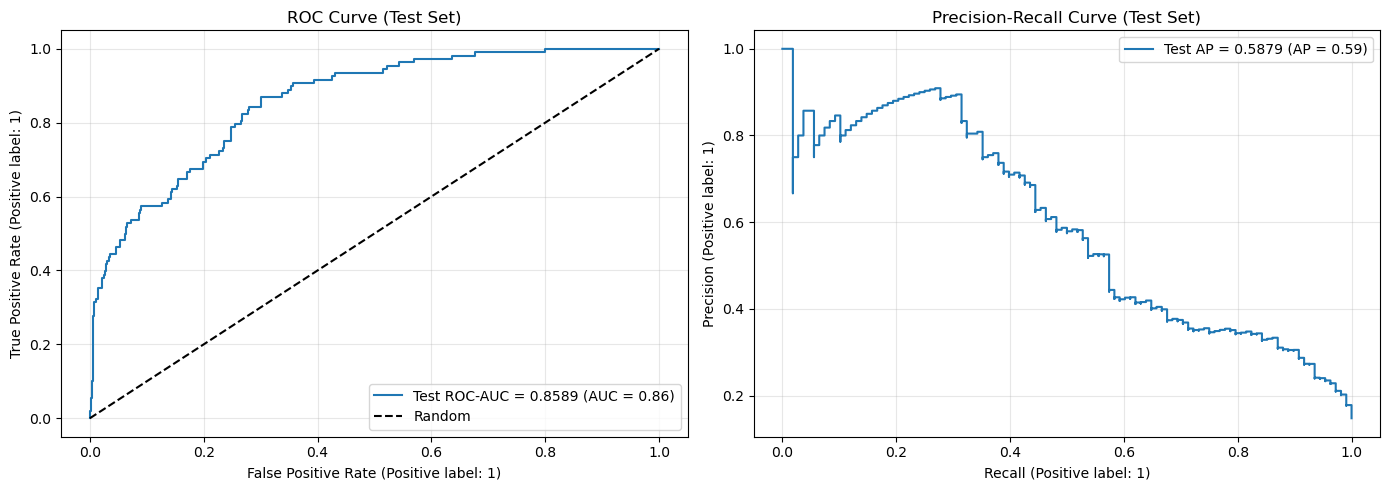

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

RocCurveDisplay.from_predictions(y_test, y_pred_proba, ax=axes[0], name=f"Test ROC-AUC = {test_auc:.4f}")
axes[0].plot([0, 1], [0, 1], 'k--', label='Random')
axes[0].set_title('ROC Curve (Test Set)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

PrecisionRecallDisplay.from_predictions(y_test, y_pred_proba, ax=axes[1], name=f"Test AP = {test_ap:.4f}")
axes[1].set_title('Precision-Recall Curve (Test Set)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
feature_names = []
cat_features = model.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(cat_cols)
feature_names.extend(cat_features)
feature_names.extend(num_cols)

print(f"Total features in model: {len(feature_names)}")
print("\nModel features (first 30):")
for i, fname in enumerate(feature_names[:30]):
    print(f"  {i+1}. {fname}")

print("\nNote: HistGradientBoostingClassifier doesn't provide direct feature importance.")
print("Use permutation_importance() or SHAP for detailed feature analysis.")


Total features in model: 483

Model features (first 30):
  1. primary_type_ARSON
  2. primary_type_ASSAULT
  3. primary_type_BATTERY
  4. primary_type_BURGLARY
  5. primary_type_CONCEALED CARRY LICENSE VIOLATION
  6. primary_type_CRIMINAL DAMAGE
  7. primary_type_CRIMINAL SEXUAL ASSAULT
  8. primary_type_CRIMINAL TRESPASS
  9. primary_type_DECEPTIVE PRACTICE
  10. primary_type_HOMICIDE
  11. primary_type_INTERFERENCE WITH PUBLIC OFFICER
  12. primary_type_INTIMIDATION
  13. primary_type_KIDNAPPING
  14. primary_type_LIQUOR LAW VIOLATION
  15. primary_type_MOTOR VEHICLE THEFT
  16. primary_type_NARCOTICS
  17. primary_type_OFFENSE INVOLVING CHILDREN
  18. primary_type_OTHER OFFENSE
  19. primary_type_PUBLIC PEACE VIOLATION
  20. primary_type_ROBBERY
  21. primary_type_SEX OFFENSE
  22. primary_type_STALKING
  23. primary_type_THEFT
  24. primary_type_WEAPONS VIOLATION
  25. description_$500 AND UNDER
  26. description_AGG. DOMESTIC BATTERY - HANDS, FISTS, FEET, SERIOUS INJURY
  27. desc

In [ ]:
print("\n" + "=" * 70)
print(" " * 20 + "FINAL MODEL SUMMARY")
print("=" * 70)
print(f"\nDataset size: {len(X)} records")
print(f"  - Train: {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)")
print(f"  - Test: {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)")
print(f"\nTarget Variable (Arrest):")
print(f"  - Overall rate: {y.mean():.4f} ({y.mean()*100:.2f}%)")
print(f"  - Train rate: {y_train.mean():.4f} ({y_train.mean()*100:.2f}%)")
print(f"  - Test rate: {y_test.mean():.4f} ({y_test.mean()*100:.2f}%)")

print(f"\nFeatures: {len(cat_cols)} categorical + {len(num_cols)} numeric = {len(feature_names)} total")

print(f"\nModel: HistGradientBoostingClassifier")
print(f"  - max_depth: 7")
print(f"  - learning_rate: 0.1")
print(f"  - max_iter: 200")
print(f"  - early_stopping: True")

print(f"\nPerformance Metrics (Test Set):")
print(f"  - ROC-AUC: {test_auc:.4f}")
print(f"  - Average Precision: {test_ap:.4f}")
print(f"  - True Positive Rate: {cm[1,1]/(cm[1,0]+cm[1,1]):.4f}")
print(f"  - True Negative Rate: {cm[0,0]/(cm[0,0]+cm[0,1]):.4f}")

print("\n" + "=" * 70)
print("Model is ready for predictions on new data!")
print("=" * 70)



                    FINAL MODEL SUMMARY

Dataset size: 3658 records
  - Train: 2926 (80.0%)
  - Test: 732 (20.0%)

Target Variable (Arrest):
  - Overall rate: 0.1482 (14.82%)
  - Train rate: 0.1483 (14.83%)
  - Test rate: 0.1475 (14.75%)

Features: 8 categorical + 12 numeric = 483 total

Model: HistGradientBoostingClassifier
  - max_depth: 7
  - learning_rate: 0.1
  - max_iter: 200
  - early_stopping: True

Performance Metrics (Test Set):
  - ROC-AUC: 0.8589
  - Average Precision: 0.5879
  - True Positive Rate: 0.3426
  - True Negative Rate: 0.9856

Model is ready for predictions on new data!


In [ ]:
sample_data = pd.DataFrame({
    "primary_type": ["THEFT", "ASSAULT", "ROBBERY", "BURGLARY", "HOMICIDE"],
    "description": ["$500 AND UNDER", "SIMPLE", "ARMED - HANDGUN", "FORCIBLE ENTRY", "FIRST DEGREE MURDER"],
    "location_description": ["STREET", "APARTMENT", "STORE", "RESIDENTIAL", "STREET"],
    "iucr": ["0820", "0460", "0312", "0610", "0110"],
    "fbi_code": ["6", "4B", "3", "5", "1A"],
    "district": [3, 5, 7, 2, 1],
    "ward": [8, 15, 22, 10, 5],
    "community_area": [35, 38, 40, 20, 28],
    "beat": [314, 515, 722, 210, 115],
    "season": ["winter", "spring", "summer", "fall", "winter"],
    "hour": [14, 19, 22, 2, 20],
    "dayofweek": [2, 5, 3, 1, 0],
    "month": [1, 4, 7, 10, 1],
    "is_weekend": [0, 0, 0, 0, 1],
    "is_night": [0, 0, 1, 1, 0],
    "latitude": [41.85, 41.87, 41.89, 41.82, 41.88],
    "longitude": [-87.65, -87.62, -87.68, -87.70, -87.63],
    "domestic": [0, 1, 0, 0, 0],
    "lat_bin": ["(41.84, 41.86]", "(41.86, 41.88]", "(41.88, 41.9]", "(41.8, 41.82]", "(41.88, 41.9]"],
    "lon_bin": ["(-87.67, -87.64]", "(-87.65, -87.62]", "(-87.7, -87.67]", "(-87.72, -87.7]", "(-87.64, -87.62]"]
})

print("Sample Crime Records to Predict:")
print(sample_data[["primary_type", "description", "location_description", "hour", "dayofweek"]].to_string(index=False))

predictions = model.predict(sample_data)
probabilities = model.predict_proba(sample_data)[:, 1]

results = pd.DataFrame({
    "Crime Type": sample_data["primary_type"],
    "Location": sample_data["location_description"],
    "Hour": sample_data["hour"],
    "Predicted Arrest": predictions,
    "Arrest Probability": probabilities.round(4),
    "Arrest %": (probabilities * 100).round(2)
})

print("\n" + "=" * 80)
print("PREDICTIONS ON NEW DATA")
print("=" * 80)
print(results.to_string(index=False))
print("=" * 80)

num_arrests = predictions.sum()
print(f"\nOut of {len(predictions)} crime records:")
print(f"  - Predicted arrests: {num_arrests}")
print(f"  - Predicted no arrest: {len(predictions) - num_arrests}")
print(f"  - Average arrest probability: {probabilities.mean():.2%}")


Sample Crime Records to Predict:
primary_type         description location_description  hour  dayofweek
       THEFT      $500 AND UNDER               STREET    14          2
     ASSAULT              SIMPLE            APARTMENT    19          5
     ROBBERY     ARMED - HANDGUN                STORE    22          3
    BURGLARY      FORCIBLE ENTRY          RESIDENTIAL     2          1
    HOMICIDE FIRST DEGREE MURDER               STREET    20          0

PREDICTIONS ON NEW DATA
Crime Type    Location  Hour  Predicted Arrest  Arrest Probability  Arrest %
     THEFT      STREET    14                 0              0.0119      1.19
   ASSAULT   APARTMENT    19                 0              0.1256     12.56
   ROBBERY       STORE    22                 0              0.0314      3.14
  BURGLARY RESIDENTIAL     2                 0              0.0040      0.40
  HOMICIDE      STREET    20                 0              0.0649      6.49

Out of 5 crime records:
  - Predicted arrests: 0
  - 

In [ ]:
print("\n" + "=" * 80)
print("SCENARIO 1: Different Crime Types (Same Location & Time)")
print("=" * 80)

scenario1 = pd.DataFrame({
    "primary_type": ["THEFT", "ROBBERY", "ASSAULT", "BURGLARY", "MOTOR VEHICLE THEFT", "NARCOTICS"],
    "description": ["$500 AND UNDER", "ARMED - HANDGUN", "SIMPLE", "FORCIBLE ENTRY", "CAR - STOLEN", "POSS: CRACK COCAINE"],
    "location_description": ["STREET", "STREET", "STREET", "STREET", "STREET", "STREET"],
    "iucr": ["0820", "0312", "0460", "0610", "1153", "1811"],
    "fbi_code": ["6", "3", "4B", "5", "7", "18"],
    "district": [3, 3, 3, 3, 3, 3],
    "ward": [8, 8, 8, 8, 8, 8],
    "community_area": [35, 35, 35, 35, 35, 35],
    "beat": [314, 314, 314, 314, 314, 314],
    "season": ["spring", "spring", "spring", "spring", "spring", "spring"],
    "hour": [14, 14, 14, 14, 14, 14],
    "dayofweek": [2, 2, 2, 2, 2, 2],
    "month": [4, 4, 4, 4, 4, 4],
    "is_weekend": [0, 0, 0, 0, 0, 0],
    "is_night": [0, 0, 0, 0, 0, 0],
    "latitude": [41.85, 41.85, 41.85, 41.85, 41.85, 41.85],
    "longitude": [-87.65, -87.65, -87.65, -87.65, -87.65, -87.65],
    "domestic": [0, 0, 0, 0, 0, 0],
    "lat_bin": ["(41.84, 41.86]", "(41.84, 41.86]", "(41.84, 41.86]", "(41.84, 41.86]", "(41.84, 41.86]", "(41.84, 41.86]"],
    "lon_bin": ["(-87.67, -87.64]", "(-87.67, -87.64]", "(-87.67, -87.64]", "(-87.67, -87.64]", "(-87.67, -87.64]", "(-87.67, -87.64]"]
})

pred1 = model.predict(scenario1)
prob1 = model.predict_proba(scenario1)[:, 1]

result1 = pd.DataFrame({
    "Crime Type": scenario1["primary_type"],
    "Arrest Probability": (prob1 * 100).round(2),
    "Predicted": ["YES" if p == 1 else "NO" for p in pred1]
})

print(result1.to_string(index=False))
print(f"\nHighest arrest probability: {scenario1['primary_type'].values[prob1.argmax()]} ({prob1.max()*100:.2f}%)")
print(f"Lowest arrest probability: {scenario1['primary_type'].values[prob1.argmin()]} ({prob1.min()*100:.2f}%)")

print("\n" + "=" * 80)
print("SCENARIO 2: Time of Day Impact (Theft at Different Hours)")
print("=" * 80)

hours = list(range(0, 24, 3))
scenario2 = pd.DataFrame({
    "primary_type": ["THEFT"] * len(hours),
    "description": ["$500 AND UNDER"] * len(hours),
    "location_description": ["STREET"] * len(hours),
    "iucr": ["0820"] * len(hours),
    "fbi_code": ["6"] * len(hours),
    "district": [3] * len(hours),
    "ward": [8] * len(hours),
    "community_area": [35] * len(hours),
    "beat": [314] * len(hours),
    "season": ["spring"] * len(hours),
    "hour": hours,
    "dayofweek": [2] * len(hours),
    "month": [4] * len(hours),
    "is_weekend": [0] * len(hours),
    "is_night": [1 if h in [22, 23, 0, 1, 2, 3, 4, 5] else 0 for h in hours],
    "latitude": [41.85] * len(hours),
    "longitude": [-87.65] * len(hours),
    "domestic": [0] * len(hours),
    "lat_bin": ["(41.84, 41.86]"] * len(hours),
    "lon_bin": ["(-87.67, -87.64]"] * len(hours)
})

pred2 = model.predict(scenario2)
prob2 = model.predict_proba(scenario2)[:, 1]

result2 = pd.DataFrame({
    "Hour": hours,
    "Time": [f"{h:02d}:00" for h in hours],
    "Is Night": scenario2["is_night"],
    "Arrest Probability %": (prob2 * 100).round(2)
})

print(result2.to_string(index=False))
print(f"\nHighest risk hour: {result2.loc[prob2.argmax(), 'Time']} ({prob2.max()*100:.2f}%)")
print(f"Lowest risk hour: {result2.loc[prob2.argmin(), 'Time']} ({prob2.min()*100:.2f}%)")

print("\n" + "=" * 80)
print("SCENARIO 3: Domestic vs Non-Domestic Incidents")
print("=" * 80)

scenario3 = pd.DataFrame({
    "primary_type": ["ASSAULT", "ASSAULT"],
    "description": ["SIMPLE", "SIMPLE"],
    "location_description": ["APARTMENT", "STREET"],
    "iucr": ["0460", "0460"],
    "fbi_code": ["4B", "4B"],
    "district": [5, 5],
    "ward": [15, 15],
    "community_area": [38, 38],
    "beat": [515, 515],
    "season": ["winter", "winter"],
    "hour": [19, 19],
    "dayofweek": [5, 5],
    "month": [1, 1],
    "is_weekend": [0, 0],
    "is_night": [0, 0],
    "latitude": [41.87, 41.87],
    "longitude": [-87.62, -87.62],
    "domestic": [1, 0],
    "lat_bin": ["(41.86, 41.88]", "(41.86, 41.88]"],
    "lon_bin": ["(-87.65, -87.62]", "(-87.65, -87.62]"]
})

pred3 = model.predict(scenario3)
prob3 = model.predict_proba(scenario3)[:, 1]

result3 = pd.DataFrame({
    "Incident Type": ["Domestic Assault", "Non-Domestic Assault"],
    "Location": scenario3["location_description"],
    "Domestic": scenario3["domestic"],
    "Arrest Probability %": (prob3 * 100).round(2),
    "Predicted": ["YES" if p == 1 else "NO" for p in pred3]
})

print(result3.to_string(index=False))
domestic_diff = abs(prob3[0] - prob3[1]) * 100
print(f"\nDifference: {domestic_diff:.2f}%")

print("\n" + "=" * 80)
print("SCENARIO 4: Weekend vs Weekday Impact (Robbery)")
print("=" * 80)

scenario4 = pd.DataFrame({
    "primary_type": ["ROBBERY"] * 7,
    "description": ["ARMED - HANDGUN"] * 7,
    "location_description": ["STORE"] * 7,
    "iucr": ["0312"] * 7,
    "fbi_code": ["3"] * 7,
    "district": [7] * 7,
    "ward": [22] * 7,
    "community_area": [40] * 7,
    "beat": [722] * 7,
    "season": ["summer"] * 7,
    "hour": [22] * 7,
    "dayofweek": [0, 1, 2, 3, 4, 5, 6],
    "month": [7] * 7,
    "is_weekend": [0, 0, 0, 0, 0, 1, 1],
    "is_night": [1] * 7,
    "latitude": [41.89] * 7,
    "longitude": [-87.68] * 7,
    "domestic": [0] * 7,
    "lat_bin": ["(41.88, 41.9]"] * 7,
    "lon_bin": ["(-87.7, -87.67]"] * 7
})

pred4 = model.predict(scenario4)
prob4 = model.predict_proba(scenario4)[:, 1]

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
result4 = pd.DataFrame({
    "Day": days,
    "Day of Week": scenario4["dayofweek"],
    "Is Weekend": scenario4["is_weekend"],
    "Arrest Probability %": (prob4 * 100).round(2)
})

print(result4.to_string(index=False))
print(f"\nWeekday average: {prob4[:-2].mean()*100:.2f}%")
print(f"Weekend average: {prob4[-2:].mean()*100:.2f}%")



SCENARIO 1: Different Crime Types (Same Location & Time)
         Crime Type  Arrest Probability Predicted
              THEFT                1.19        NO
            ROBBERY                2.58        NO
            ASSAULT               11.02        NO
           BURGLARY                0.60        NO
MOTOR VEHICLE THEFT                9.33        NO
          NARCOTICS               90.64       YES

Highest arrest probability: NARCOTICS (90.64%)
Lowest arrest probability: BURGLARY (0.60%)

SCENARIO 2: Time of Day Impact (Theft at Different Hours)
 Hour  Time  Is Night  Arrest Probability %
    0 00:00         1                  1.16
    3 03:00         1                  1.54
    6 06:00         0                  1.19
    9 09:00         0                  1.19
   12 12:00         0                  1.19
   15 15:00         0                  1.30
   18 18:00         0                  1.46
   21 21:00         0                  1.46

Highest risk hour: 03:00 (1.54%)
Lowest risk